# Combinatorial Optimization Problems: Overview

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt

from core.problems.cvrp import CVRPConfig, get_cvrp_generator, visualize_cvrp_instance
from core.problems.op import OPConfig, get_op_generator, visualize_op_instance
from core.problems.tsp import TensorTSPSampler, TSPConfig, TSPInstance

## Traveling Salesman Problem

tensor([[0.8419, 0.0078],
        [0.3767, 0.3148],
        [0.8046, 0.7898],
        [0.7254, 0.2765],
        [0.0826, 0.3747],
        [0.0423, 0.2569],
        [0.7597, 0.3049],
        [0.1903, 0.7774],
        [0.9158, 0.1840],
        [0.4030, 0.2669],
        [0.9110, 0.8771],
        [0.0231, 0.5216],
        [0.3211, 0.2346],
        [0.6495, 0.6266],
        [0.5871, 0.0379],
        [0.2074, 0.8349],
        [0.4956, 0.3596],
        [0.1793, 0.3357],
        [0.8763, 0.9235],
        [0.9687, 0.7170]])


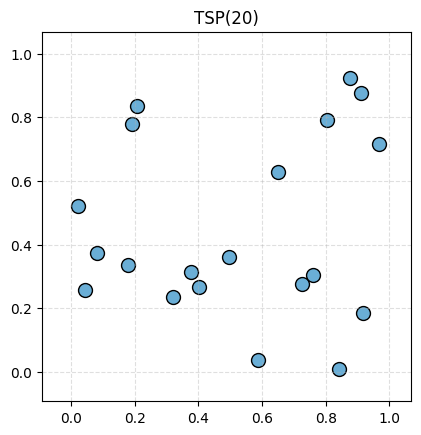

In [2]:
tsp_config = TSPConfig(num_locations=20)
tsp_sampler = TensorTSPSampler(tsp_config)
t = tsp_sampler(2)
print(t[0])

TSPInstance.from_tensor(t[0]).visualize()
plt.show()

## Capacitated Vehicle Problem

TensorDict(
    fields={
        capacity: Tensor(shape=torch.Size([1, 1]), device=cpu, dtype=torch.float32, is_shared=False),
        demand: Tensor(shape=torch.Size([1, 20]), device=cpu, dtype=torch.float32, is_shared=False),
        depot: Tensor(shape=torch.Size([1, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        locs: Tensor(shape=torch.Size([1, 20, 2]), device=cpu, dtype=torch.float32, is_shared=False)},
    batch_size=torch.Size([1]),
    device=None,
    is_shared=False)


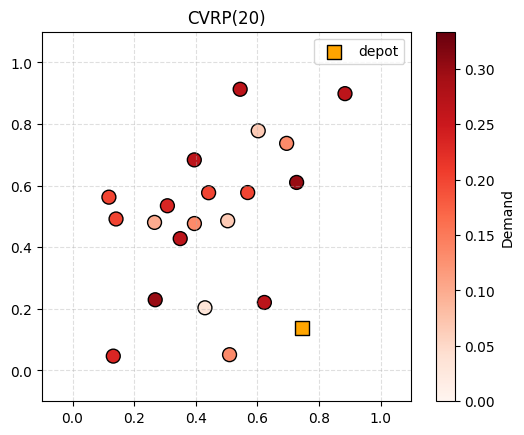

In [9]:
cvrp_config = CVRPConfig(num_nodes=20)
cvrp_generator = get_cvrp_generator(cvrp_config)
td = cvrp_generator([1])
print(td)

capacity = td[0]["capacity"].item()
min_loc = cvrp_generator.min_loc
max_loc = cvrp_generator.max_loc
min_demand = cvrp_generator.min_demand / capacity
max_demand = cvrp_generator.max_demand / capacity

visualize_cvrp_instance(td[0], min_loc, max_loc, max_demand)
plt.show()

## Orienteering Problem

**1. Constant**

TensorDict(
    fields={
        depot: Tensor(shape=torch.Size([1, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        locs: Tensor(shape=torch.Size([1, 20, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        max_length: Tensor(shape=torch.Size([1]), device=cpu, dtype=torch.float32, is_shared=False),
        prize: Tensor(shape=torch.Size([1, 20]), device=cpu, dtype=torch.float32, is_shared=False)},
    batch_size=torch.Size([1]),
    device=None,
    is_shared=False)
TensorDict(
    fields={
        depot: Tensor(shape=torch.Size([2]), device=cpu, dtype=torch.float32, is_shared=False),
        locs: Tensor(shape=torch.Size([20, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        max_length: Tensor(shape=torch.Size([]), device=cpu, dtype=torch.float32, is_shared=False),
        prize: Tensor(shape=torch.Size([20]), device=cpu, dtype=torch.float32, is_shared=False)},
    batch_size=torch.Size([]),
    device=None,
    is_shared=False)


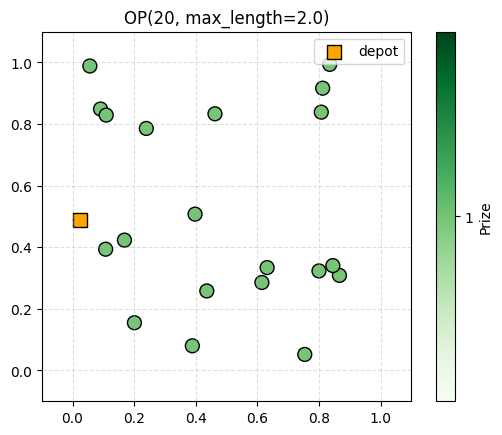

In [10]:
op_config = OPConfig(num_nodes=20, prize_type="const")
op_generator = get_op_generator(op_config)
op_generator.device = "cpu"
td = op_generator([1])
print(td)

print(td[0])

min_loc = op_generator.min_loc
max_loc = op_generator.max_loc

visualize_op_instance(td[0], min_loc, max_loc, prize_type="const")
plt.show()

**2. Uniform**

TensorDict(
    fields={
        depot: Tensor(shape=torch.Size([1, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        locs: Tensor(shape=torch.Size([1, 20, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        max_length: Tensor(shape=torch.Size([1]), device=cpu, dtype=torch.float32, is_shared=False),
        prize: Tensor(shape=torch.Size([1, 20]), device=cpu, dtype=torch.float32, is_shared=False)},
    batch_size=torch.Size([1]),
    device=None,
    is_shared=False)


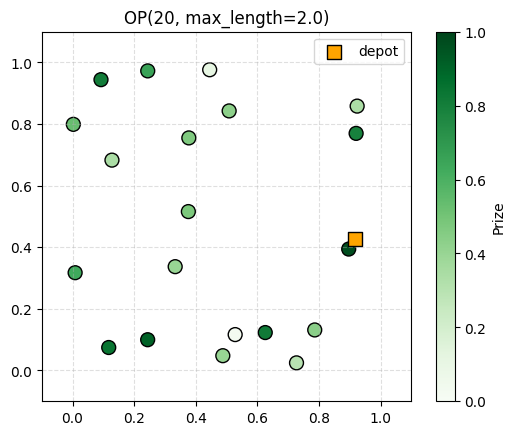

In [11]:
op_config = OPConfig(num_nodes=20, prize_type="unif")
op_generator = get_op_generator(op_config)
op_generator.device = "cpu"
td = op_generator([1])
print(td)

min_loc = op_generator.min_loc
max_loc = op_generator.max_loc

locations = td["locs"][0].cpu().numpy()
depot = td["depot"][0].cpu().numpy()
prizes = td["prize"][0].cpu().numpy()
max_length = td["max_length"][0].item()

visualize_op_instance(td[0], min_loc, max_loc, prize_type="unif")
plt.show()

**3. Distance**

TensorDict(
    fields={
        depot: Tensor(shape=torch.Size([1, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        locs: Tensor(shape=torch.Size([1, 20, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        max_length: Tensor(shape=torch.Size([1]), device=cpu, dtype=torch.float32, is_shared=False),
        prize: Tensor(shape=torch.Size([1, 20]), device=cpu, dtype=torch.float32, is_shared=False)},
    batch_size=torch.Size([1]),
    device=None,
    is_shared=False)


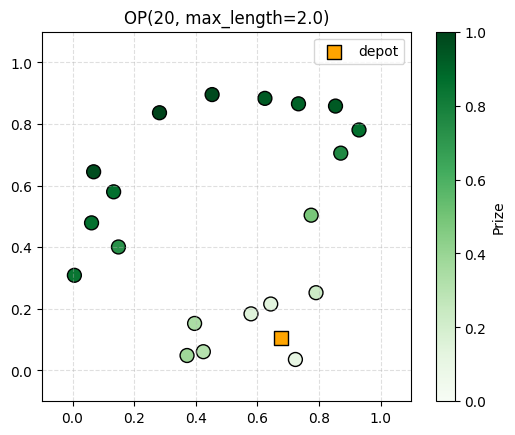

In [12]:
op_config = OPConfig(num_nodes=20, prize_type="dist")
op_generator = get_op_generator(op_config)
td = op_generator([1])
print(td)

min_loc = op_generator.min_loc
max_loc = op_generator.max_loc

visualize_op_instance(td[0], min_loc, max_loc, prize_type="dist")
plt.show()